# Day 1 lecture: Foundations of data-driven decisions

<p class="lead">
The first three periods of Day 1. Why organisations decide with data and how famous decisions went right and wrong; the four levels of analytics, from describing the past to recommending an action; how to turn a vague business question into something data can answer; what "good data" means; and why a table of summary statistics is never enough on its own.
</p>

Run each code cell with **Shift + Enter**, in order. The notebook makes its own synthetic data, except Part 6, which reads `data/datasaurus_dozen.csv`.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder; everything loads from `data/`.
- **Route A (Try JupyterLab):** upload this notebook and `data/datasaurus_dozen.csv`, run `%pip install seaborn` in a first cell, and change `"data/datasaurus_dozen.csv"` to `"datasaurus_dozen.csv"` in Part 6.

---

## What you will be able to do

1. Explain, with real cases, what data adds to a decision, and name the ways data-driven decisions fail.
2. Place any business question on the **analytics hierarchy** (descriptive, diagnostic, predictive, prescriptive) and say what each level can and cannot tell you.
3. **Frame** a decision: name the decision, the population, the period and the measure, and show how each choice changes the answer.
4. Check a table against six **data quality dimensions** with short pandas tests.
5. Explain, using Anscombe's quartet and the Datasaurus Dozen, why you must always plot data before trusting its summary.

| Part | Topic | Period |
|---|---|---|
| 1 | Welcome: the course on one page | P1 |
| 2 | Why decide with data, and how it goes wrong | P1 |
| 3 | The analytics hierarchy, with a worked example | P2 |
| 4 | Framing a decision: decision, population, period, measure | P3 |
| 5 | Data quality dimensions | P3 |
| 6 | Why summary statistics are not enough | P3 |
| 7 | Business case, practice, quiz and summary | P3 and self-study |

> **Reading**
>
> Read Chapter 1 of the course reading packet for the four levels of analytics carried through a single worked example, for how to read a page of industry statistics with healthy suspicion, and for what `describe()`, `isnull().sum()`, `groupby()` and correlation each reveal. This lecture goes further on cases, framing and data quality.

---

## Part 1: Welcome: the course on one page

DATA 300 is about one habit: **before you act, ask what the evidence says, and how sure you can be**. You will practise it in three programs, each graded:

| Program | Used for | Days |
|---|---|---|
| JupyterLab (Python) | Exploring data, text mining, forecasting, regression | 1, 3, 4, 5 |
| Tableau Desktop | Dashboards and visual communication | 2, 6 |
| Microsoft Excel | Spreadsheet models, What-If tables, simulation, forecast sheets | 5, 6 |

How each day works: theory in the morning, a lab in the afternoon that you submit on GAP **the same day**. Today's lab is Lab 1, data exploration on a dataset of diamonds. The [overview](index.md) lists every graded item and its weight; the [timetable](timetable.md) shows each period.

Three habits save more marks than any formula:

1. **Restart and run all** before you export, so the PDF matches the code.
2. **Export a PDF before closing** a Try JupyterLab tab; the session lives only in the browser.
3. **Write the unit** with every number: US dollars, grams, minutes, per cent.

> **Check your understanding**
>
> Which of the three programs keeps your work only as long as a browser tab is open, and what do you do about it?

---

## Part 2: Why decide with data, and how it goes wrong

Every organisation already decides. The question is what the decision rests on: habit, the loudest voice in the room, a competitor's move, or evidence. Data helps in three ways:

- It **replaces memory with records**. People remember vivid events (the one angry customer, the record sales day) and forget ordinary ones. A table remembers them all equally.
- It **makes a claim checkable**. "Sales are down in the north" can be tested; "I have a feeling" cannot.
- It **scales judgement**. A rule that worked for one store manager can be applied to 500 stores, and its results measured.

Data does **not** replace judgement. People still choose which question matters, decide whether a strange number is an error or a discovery, weigh values that no column records (fairness, safety, reputation) and take responsibility for the action.

### Biases that data can correct, if it is used honestly

| Bias | What it looks like | How data helps |
|---|---|---|
| Availability | Judging by the examples that come to mind most easily | Count all the cases, not the memorable ones |
| Confirmation | Looking only for evidence that supports what you already believe | Decide the test before you look at the result |
| Survivorship | Studying only the cases that "made it" | Ask which cases are missing from the table, and why |
| Anchoring | Sticking to the first number you heard | Compare against a baseline chosen in advance |
| Overconfidence | Treating one good quarter as a law | Look at variation over many periods |

### Cases: when data helped, and when it failed

These are well-known, widely reported cases, summarised in our own words. Details differ between sources; the references at the end of this notebook give a place to start.

| Case | What happened | Level of analytics | Lesson |
|---|---|---|---|
| Walmart before a hurricane (2004) | Analysts looked at sales records from earlier storms and found that, besides water and torches, some unexpected items (a breakfast pastry, beer) sold far above normal. Stores in the storm's path were stocked accordingly | Descriptive, used for prediction | Past records can reveal demand nobody would guess |
| Parcel route planning (UPS ORION, 2010s) | An optimisation system proposes the order of each driver's stops; the company reports large savings in miles and fuel each year | Prescriptive | Recommending an action needs a good model of costs and constraints |
| Airline revenue management (1980s onward) | Airlines forecast demand for each fare class and decide how many seats to sell at each price | Predictive and prescriptive | A forecast becomes valuable when it changes a decision |
| A 1936 US election poll (*Literary Digest*) | Over two million mailed ballots predicted a clear win for the challenger; the president won in a landslide. The mailing lists favoured wealthier households, and those who replied differed from those who did not | Descriptive, wrongly generalised | A huge sample from the **wrong population** is still wrong |
| Damage to returning aircraft (Second World War) | Planners proposed armour where returning planes had the most bullet holes. The statistician Abraham Wald argued the opposite: planes hit elsewhere had not come back | Diagnostic | The data you **cannot** see (survivorship) can reverse the conclusion |
| Space Shuttle *Challenger* (1986) | Before launch, engineers discussed O-ring damage against temperature using only flights that had damage. Including the flights with **no** damage shows the cold-weather risk much more clearly | Diagnostic | Leaving out "nothing happened" cases hides the pattern |
| Google Flu Trends (2008–2015) | Search terms were used to estimate flu levels. In the 2012–13 season the estimates were roughly double the official figures | Predictive | Correlation without a mechanism drifts; check predictions against reality |
| A home-buying algorithm (Zillow Offers, 2021) | A company bought homes based on price forecasts, then closed the business after the forecasts and the market moved apart, with large losses and job cuts | Predictive, acted on at scale | A model is only as good as its fit to **today's** conditions |
| Amazon's CV-screening tool (reported 2018) | A tool trained on ten years of past hiring learned to mark down CVs that mentioned women's activities, and was dropped | Predictive | History records past decisions, including biased ones |

> **Discuss in pairs (5 minutes)**
>
> Pick one failure from the table. Which **one** question, asked before the decision, might have caught the problem? Keep your answer: by the end of Part 4 you will see that most of these questions are about the **population**, the **period** or the **measure**.

---

## Part 3: The analytics hierarchy

Analytics questions come in four kinds. Each one needs the answer to the one before it.

| Level | Question | Typical output | Typical methods | In this course |
|---|---|---|---|---|
| **Descriptive** | What happened? | Totals, averages, rates, charts, dashboards | Summaries, pivot tables, histograms | Days 1–2, Labs 1–2, Assignment 1 |
| **Diagnostic** | Why did it happen? | Breakdowns, comparisons, drivers | Grouping, segmentation, correlation, controlled comparisons | Days 1–3 |
| **Predictive** | What is likely to happen? | Forecasts, probabilities, scores | Time series, regression, text features | Days 3–5, Labs 4–5, Assignment 2 |
| **Prescriptive** | What should we do? | A recommended action, with its expected result and risk | Optimisation, simulation, What-If analysis | Days 5–6, Labs 6–7, Assignment 3 |

Value usually rises up the table, and so do difficulty and the number of **assumptions** you must make. A descriptive number can be checked against the records; a prescription rests on a model of how the world will respond.

### The same business, four kinds of question

| Function | Descriptive | Diagnostic | Predictive | Prescriptive |
|---|---|---|---|---|
| Retail | Sales by store last month | Why did the new store under-perform? | Demand per product next week | How much of each product to order |
| Human resources | Staff turnover rate by team | Which factors go with people leaving? | Who is likely to resign this year? | Which retention offer to make, to whom |
| Finance | Overdue invoices by customer | Which customer types pay late, and when? | Probability that an invoice is paid late | Which customers get credit, and how much |
| Operations | Average delivery time | Where in the process do delays build up? | Delay risk for tomorrow's routes | How many drivers to roster per shift |
| Marketing | Campaign click rate | Which audience and message drove the clicks? | Who will respond to the next campaign? | Which customers to target within the budget |

> **Misconception: "descriptive analytics is the easy, low-value level"**
>
> Every later level is built on it. A forecast trained on wrongly described history is wrong, and a recommendation built on a wrong forecast is wrong with confidence. Most of the failures in Part 2 were descriptive or framing errors, not modelling errors.

> **Misconception: "a predictive model explains why"**
>
> A model can predict well using a column that has nothing to do with the cause (Google Flu Trends used search habits, not infections). Prediction answers *what next*, not *why*. Diagnosis and experiments answer *why*.

The hierarchy is also a **loop**, not a ladder you climb once: a prescription is acted on, the result is measured (descriptive again), and the model is corrected.

### A worked example: late deliveries at a food delivery firm

The next cell **generates** eight weeks of orders for an imaginary food delivery company, QuickBite. The data is synthetic (made by a seeded random generator, so it is identical every run). Money is in neutral **currency units**. One row is one order.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(1110)
days = pd.date_range("2026-09-07", periods=56, freq="D")          # eight weeks, Monday to Sunday
rain_today = rng.random(len(days)) < 0.3                            # about 3 days in 10 are rainy
slots = {"Lunch": 60, "Dinner": 90, "Late night": 25}               # average orders per slot

rows = []
for day, rain in zip(days, rain_today):
    for slot, mean_orders in slots.items():
        n = rng.poisson(mean_orders * (1.15 if day.dayofweek >= 5 else 1.0))
        distance = rng.gamma(2.0, 1.6, n)                           # km from restaurant to customer
        score = (-2.6 + 0.22 * distance + 1.0 * rain + 0.5 * (slot == "Dinner")
                 + 0.9 * (rain and slot == "Dinner"))
        late = rng.random(n) < 1 / (1 + np.exp(-score))             # probability of arriving late
        rows.append(pd.DataFrame({
            "date": day, "week": (day - days[0]).days // 7 + 1, "slot": slot,
            "rain": rain, "distance_km": distance.round(1), "late": late,
        }))

orders = pd.concat(rows, ignore_index=True)
print("Orders:", len(orders))
orders.head()

Orders: 10347


,date,week,slot,rain,distance_km,late
0,2026-09-07,1,Lunch,False,7.4,False
1,2026-09-07,1,Lunch,False,1.2,False
2,2026-09-07,1,Lunch,False,0.7,False
3,2026-09-07,1,Lunch,False,2.5,False
4,2026-09-07,1,Lunch,False,2.8,False


#### Level 1, descriptive: what happened?

> **Predict, then run**
>
> Roughly what share of orders do you think arrived late: 5%, 15% or 40%? Write a number, then run the cell.

Late orders over eight weeks: 25.7%


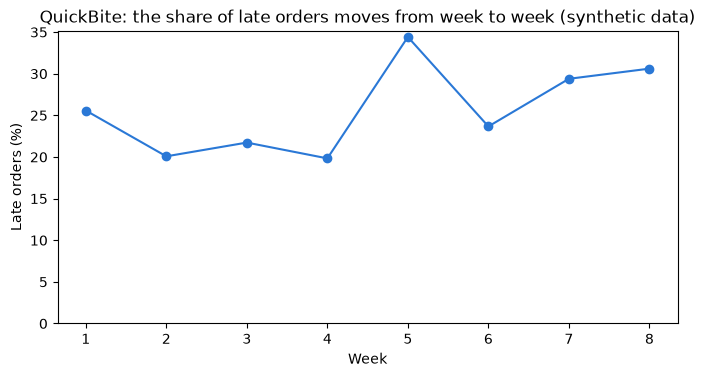

In [2]:
late_rate = orders["late"].mean() * 100          # True counts as 1, so the mean is the share
print(f"Late orders over eight weeks: {late_rate:.1f}%")

weekly = orders.groupby("week")["late"].mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(weekly.index, weekly.values, marker="o", color="#2a78d6")
ax.set_title("QuickBite: the share of late orders moves from week to week (synthetic data)")
ax.set_xlabel("Week")
ax.set_ylabel("Late orders (%)")
ax.set_ylim(0, None)
plt.show()

The mean of a True/False column is the **share** of True values: a useful trick. The weekly line moves, but descriptive analytics alone cannot say whether the movement means anything.

#### Level 2, diagnostic: why did it happen?

Diagnosis means **breaking the total into parts** and comparing them. Always show how many rows sit behind each rate.

In [3]:
late_table = pd.pivot_table(orders, index="slot", columns="rain", values="late", aggfunc="mean") * 100
late_table.columns = ["Dry day", "Rainy day"]
count_table = pd.pivot_table(orders, index="slot", columns="rain", values="late", aggfunc="count")
count_table.columns = ["Dry day", "Rainy day"]

print("Late orders (%) by slot and weather")
print(late_table.round(1))
print("\nNumber of orders behind each rate")
print(count_table)

Late orders (%) by slot and weather
            Dry day  Rainy day
slot                          
Dinner         19.5       60.5
Late night     13.7       29.2
Lunch          14.8       29.3

Number of orders behind each rate
            Dry day  Rainy day
slot                          
Dinner         3694       1637
Late night     1027        462
Lunch          2532        995


In [4]:
orders["distance_band"] = pd.cut(orders["distance_km"], bins=[0, 2, 4, 6, 30],
                                 labels=["0-2 km", "2-4 km", "4-6 km", "over 6 km"])
by_distance = orders.groupby("distance_band", observed=True)["late"].agg(["count", "mean"])
by_distance["mean"] = (by_distance["mean"] * 100).round(1)
by_distance.columns = ["orders", "late (%)"]
by_distance

,orders,late (%)
distance_band,,
0-2 km,3757,18.4
2-4 km,3679,23.7
4-6 km,1763,31.3
over 6 km,1143,47.1


> **Check your understanding**
>
> 1. Which combination of slot and weather has the highest late rate? Is it also the one with the most orders?
> 2. Do longer distances go with more late orders? Does this table **prove** that distance causes lateness? What else might be different about long-distance orders?

#### Level 3, predictive: what is likely to happen?

The simplest honest prediction uses the past rates as the forecast for the future. To see whether that works, **fit on weeks 1–6 and test on weeks 7–8**, which the "model" has not seen. This train-and-test idea returns on Days 3 and 4.

In [5]:
train = orders[orders["week"] <= 6]
test = orders[orders["week"] >= 7]

predicted = train.groupby(["slot", "rain"])["late"].mean() * 100     # the "model": past rates
actual = test.groupby(["slot", "rain"])["late"].mean() * 100

check = pd.DataFrame({"predicted (%)": predicted, "actual in weeks 7-8 (%)": actual}).round(1)
check["error (points)"] = (check["actual in weeks 7-8 (%)"] - check["predicted (%)"]).round(1)
print(check)
print(f"\nAverage size of the error: {check['error (points)'].abs().mean():.1f} percentage points")

                  predicted (%)  actual in weeks 7-8 (%)  error (points)
slot       rain                                                         
Dinner     False           19.4                     19.9             0.5
           True            58.7                     64.2             5.5
Late night False           13.2                     15.8             2.6
           True            28.2                     31.4             3.2
Lunch      False           14.5                     16.1             1.6
           True            30.2                     27.7            -2.5

Average size of the error: 2.6 percentage points


> **Predict, then run**
>
> Which row of the table would you expect to have the **largest** error, and why? (Hint: compare with the counts table above, and think about which conditions the model's past rates may not describe well.)

#### Level 4, prescriptive: what should we do?

The operations manager can pay **standby riders** for a slot. Assumptions (all of them made up for teaching, and all of them worth questioning):

- A late order costs **25 currency units** (a 15-unit voucher plus an estimate of lost future orders).
- Four standby riders cost **240 currency units** for one slot.
- Standby riders **halve** the late rate in that slot.

The prescriptive question: *in which slots does paying for standby riders save money?*

In [6]:
COST_PER_LATE = 25        # currency units per late order
RIDER_COST = 240          # currency units per slot for four standby riders
REDUCTION = 0.5           # share of late orders that standby riders prevent

def standby_plan(reduction):
    plan = train.groupby(["slot", "rain"]).agg(orders_per_slot=("late", "size"), late_rate=("late", "mean"))
    slot_days = train.groupby(["slot", "rain"])["date"].nunique()
    plan["orders_per_slot"] = plan["orders_per_slot"] / slot_days
    plan["late_cost_now"] = plan["orders_per_slot"] * plan["late_rate"] * COST_PER_LATE
    plan["late_cost_with_riders"] = plan["late_cost_now"] * (1 - reduction) + RIDER_COST
    plan["saving"] = plan["late_cost_now"] - plan["late_cost_with_riders"]
    plan["decision"] = np.where(plan["saving"] > 0, "Add riders", "Do nothing")
    plan["late_rate"] = plan["late_rate"] * 100                     # show as a percentage
    return plan.rename(columns={"late_rate": "late (%)"}).round(1)

standby_plan(REDUCTION)

orders_per_slot  late (%)  late_cost_now  \
slot       rain                                              
Dinner     False             95.0      19.4          460.5   
           True              99.0      58.7         1452.3   
Late night False             26.2      13.2           86.3   
           True              28.1      28.2          197.7   
Lunch      False             64.2      14.5          233.1   
           True              58.6      30.2          443.2   

                  late_cost_with_riders  saving    decision  
slot       rain                                              
Dinner     False                  470.2    -9.8  Do nothing  
           True                   966.1   486.1  Add riders  
Late night False                  283.1  -196.9  Do nothing  
           True                   338.9  -141.1  Do nothing  
Lunch      False                  356.5  -123.5  Do nothing  
           True                   461.6   -18.4  Do nothing

Read the result as a manager would: each row is one kind of slot, with the expected cost per slot with and without standby riders. The decision column is the **prescription**.

> **Predict, then run: how fragile is the prescription?**
>
> Suppose the riders prevent only **a quarter** of late orders, not half. Which decisions change, and what happens to the saving on rainy dinners? Predict, then run the next cell.

In [7]:
standby_plan(0.25)[["late_cost_now", "late_cost_with_riders", "saving", "decision"]]

late_cost_now  late_cost_with_riders  saving    decision
slot       rain                                                           
Dinner     False          460.5                  585.4  -124.9  Do nothing
           True          1452.3                 1329.2   123.1  Add riders
Late night False           86.3                  304.7  -218.4  Do nothing
           True           197.7                  388.3  -190.6  Do nothing
Lunch      False          233.1                  414.8  -181.7  Do nothing
           True           443.2                  572.4  -129.2  Do nothing

The prescription depends on an assumption nobody has measured. Before a full rollout, the honest next step is a **trial**: add riders on some rainy dinners and not others, and measure the difference. That is the loop from prescriptive back to descriptive, and it is how Days 5 and 6 treat uncertainty.

> **Statistic, insight, decision**
>
> - **Statistic:** "x% of rainy dinner orders were late."
> - **Insight:** "Rain at dinner time is where lateness concentrates, and a late order costs us about 25 units."
> - **Decision:** "Trial standby riders on rainy dinners for four weeks, and keep them if the late rate falls by at least a third."
>
> A statistic is a number. An insight says what it means for the business. A decision says what we will do, and how we will know if it worked.

---

## Part 4: Framing a decision

Most analysis goes wrong **before** any code runs, because the question was vague. "How are our branches doing?" cannot be answered; it can only be argued about. A framed question names four things:

| Element | Ask | Example |
|---|---|---|
| **Decision** | What will someone do differently depending on the answer? | Move the senior barista to the weaker branch, or not |
| **Population** | Which rows count? Who or what is in, and who is out? | Customer orders only: no staff meals, no test orders, no refunds |
| **Period** | Which time window, and why that one? | The last eight full weeks, after the menu change |
| **Measure** | Which number, calculated how? | Median order value in currency units, per order |

Add a **comparison** (against what? last year, a target, another branch) and a **threshold** (how big a difference would change the decision?), and the question is ready.

### Reframing vague questions

| Vague | Framed |
|---|---|
| Are customers happy? | Should we fix delivery packaging first? Compare the share of 1–2 star reviews mentioning packaging versus delivery time, for reviews of orders placed in September–October, app orders only |
| Is the promotion working? | Should we extend the promotion to all stores? Compare weekly units sold per store in the 10 promotion stores and 10 similar stores without it, for the four weeks before and the four weeks during the promotion |
| Who are our best customers? | Which customers should get a loyalty invitation? Rank active customers (ordered in the last 90 days) by gross margin over the last 12 months; invite the top 5% |

### Every choice changes the answer

The next cell generates twelve weeks of orders for two branches of an imaginary bakery chain. The **East** branch had three big catering orders early on; both branches have some **test orders** placed by staff, and the **West** branch was **refurbished** in weeks 1–4, when it sold a reduced menu and staff placed many test orders on the new tills.

In [8]:
rng = np.random.default_rng(11)
frames = []
for branch in ["East", "West"]:
    for week in range(1, 13):
        refurbishing = branch == "West" and week <= 4                   # West branch weeks 1-4
        n = 150 if refurbishing else 160
        typical = 44 if branch == "East" else (28 if refurbishing else 47)
        value = rng.lognormal(np.log(typical), 0.45, n)
        test = rng.random(n) < (0.25 if refurbishing else 0.03)         # staff tested the new tills
        frames.append(pd.DataFrame({"branch": branch, "week": week,
                                    "order_value": value.round(2), "test_order": test}))
bakery = pd.concat(frames, ignore_index=True)
catering = pd.DataFrame({"branch": "East", "week": [1, 2, 3], "order_value": [2400.0, 3100.0, 2750.0],
                         "test_order": False})
bakery = pd.concat([bakery, catering], ignore_index=True)
bakery.loc[bakery["test_order"], "order_value"] = 0.01          # staff test orders are recorded at 0.01
print("Rows:", len(bakery))
bakery.groupby("branch")["order_value"].describe().round(2)

Rows: 3803


,count,mean,std,min,25%,50%,75%,max
branch,,,,,,,,
East,1923.0,51.79,110.01,0.01,31.97,43.46,58.94,3100.0
West,1880.0,43.35,27.81,0.01,25.65,39.81,56.88,204.9


The manager asks: **"Which branch has the higher average order value?"** Here are four defensible answers to that one question.

> **Predict, then run**
>
> Before running: which branch do you think "wins" if we use the plain mean over all twelve weeks? Will it still win with the median, or when we use only the weeks in which both branches traded normally?

In [9]:
customers_only = bakery[~bakery["test_order"]]
recent = customers_only[customers_only["week"] >= 5]

answers = pd.DataFrame({
    "Mean, all rows, 12 weeks": bakery.groupby("branch")["order_value"].mean(),
    "Mean, customers only, 12 weeks": customers_only.groupby("branch")["order_value"].mean(),
    "Median, customers only, 12 weeks": customers_only.groupby("branch")["order_value"].median(),
    "Median, customers only, weeks 5-12": recent.groupby("branch")["order_value"].median(),
}).T.round(2)
answers["higher"] = np.where(answers["East"] > answers["West"], "East", "West")
answers

branch,East,West,higher
"Mean, all rows, 12 weeks",51.79,43.35,East
"Mean, customers only, 12 weeks",53.34,47.33,East
"Median, customers only, 12 weeks",44.28,42.10,East
"Median, customers only, weeks 5-12",44.66,48.06,West


Every number in that table is **correct**. They answer different questions:

- The **population** choice (dropping test orders) removes rows that are not customers at all, and moves both means.
- The **measure** choice (mean or median) decides how much three huge catering orders count: compare the size of East's lead under each.
- The **period** choice (from week 5) removes the refurbishment, when the West branch was not trading normally, and here it reverses the answer.

None of these choices is automatically right. If the decision is about catering sales, the mean with catering orders is exactly what you want. That is why framing starts from the **decision**.

> **Misconception: "the data will tell us which number to use"**
>
> It will not. The decision tells you which number to use. Choose the population, period and measure **before** looking at the result, and write them down; otherwise it is easy to pick, without meaning to, the version that supports what you already believed (confirmation bias from Part 2).

> **Check your understanding**
>
> Look again at the *Literary Digest* poll and the *Challenger* case in Part 2. Which framing element (decision, population, period, measure) went wrong in each?

---

## Part 5: Data quality dimensions

"Is the data good?" is another vague question. Data quality is usually split into dimensions, each with its own test. Data is never perfect; the question is whether it is **fit for this decision**.

| Dimension | Question | Typical pandas check |
|---|---|---|
| **Completeness** | Is anything missing? | `df.isnull().sum()` |
| **Uniqueness** | Is anything counted twice? | `df.duplicated().sum()`, or duplicates on an ID column |
| **Validity** | Are values allowed and in range? | `describe()` min and max; a filter for impossible values |
| **Consistency** | Is the same thing written the same way everywhere? | `value_counts()` on text columns |
| **Accuracy** | Do values match reality? | Compare with a trusted source; spot-check rows |
| **Timeliness** | Is it recent enough for the decision? | `max()` of the date column against today |

Here is a tiny customer sign-up table with problems planted in it. Each check below finds one dimension's problems.

In [10]:
signups = pd.DataFrame({
    "customer_id": [101, 102, 103, 104, 104, 105, 106, 107, 108, 109],
    "country": ["China", "China", "CN", "Japan", "Japan", "china", "Korea", "China", "Japan", None],
    "age": [23, 31, 27, 240, 240, 35, -1, 29, 41, 22],
    "email": ["a@x.cn", "b@x.cn", None, "d@x.jp", "d@x.jp", "e@x.cn", "f@x.kr", None, "h@x.jp", "i@x.cn"],
    "signed_up": pd.to_datetime(["2026-03-02", "2026-03-05", "2026-03-09", "2026-04-11", "2026-04-11",
                                 "2026-05-20", "2026-06-01", "2026-06-14", "2027-01-15", "2026-06-30"]),
})
signups

,customer_id,country,age,email,signed_up
0,101,China,23,a@x.cn,2026-03-02
1,102,China,31,b@x.cn,2026-03-05
2,103,CN,27,None,2026-03-09
3,104,Japan,240,d@x.jp,2026-04-11
4,104,Japan,240,d@x.jp,2026-04-11
5,105,china,35,e@x.cn,2026-05-20
6,106,Korea,-1,f@x.kr,2026-06-01
7,107,China,29,None,2026-06-14
8,108,Japan,41,h@x.jp,2027-01-15
9,109,None,22,i@x.cn,2026-06-30


In [11]:
today = pd.Timestamp("2026-11-10")      # the date of this lecture, fixed so the output never changes

print("Completeness: missing values per column")
print(signups.isnull().sum(), "\n")

print("Uniqueness: fully repeated rows:", signups.duplicated().sum(),
      "| repeated customer IDs:", signups["customer_id"].duplicated().sum(), "\n")

print("Validity: ages outside 16-100")
print(signups[(signups["age"] < 16) | (signups["age"] > 100)][["customer_id", "age"]], "\n")

print("Consistency: how country is written")
print(signups["country"].value_counts(dropna=False), "\n")

print("Timeliness and validity: sign-up dates after today")
print(signups[signups["signed_up"] > today][["customer_id", "signed_up"]])
print("Most recent sign-up on file:", signups["signed_up"].max().date())

Completeness: missing values per column
customer_id    0
country        1
age            0
email          2
signed_up      0
dtype: int64 

Uniqueness: fully repeated rows: 1 | repeated customer IDs: 1 

Validity: ages outside 16-100
   customer_id  age
3          104  240
4          104  240
6          106   -1 

Consistency: how country is written
country
China    3
Japan    3
CN       1
china    1
Korea    1
None     1
Name: count, dtype: int64 

Timeliness and validity: sign-up dates after today
   customer_id  signed_up
8          108 2027-01-15
Most recent sign-up on file: 2027-01-15


> **Predict, then run**
>
> If you calculate the average age **before** fixing anything, will it be too high or too low, and roughly by how much? Run `signups["age"].mean()` in a new cell, then compare with the mean of the valid ages only.

Notice what pandas could **not** check. Whether customer 102 really is 31 (accuracy) needs a trusted outside source. Whether data that stops in June is recent enough (timeliness) depends on the decision: fine for a yearly report, useless for this week's campaign.

> **Misconception: "clean the data, then analyse it"**
>
> Cleaning is a set of decisions, and each one changes the answer. Dropping the row with age 240 is reasonable; dropping every row with a missing email would remove 20% of customers. Record every cleaning step and its reason, so a reader can judge it.

> **Check your understanding**
>
> For each planted problem in `signups`, name the dimension and the fix you would make. Which problems would you fix in the data, and which would you report back to whoever collects it?

---

## Part 6: Why summary statistics are not enough

### Anscombe's quartet

In 1973 the statistician Francis Anscombe built four small datasets that share almost the same summary statistics. The values are below; they are public and widely reproduced.

In [12]:
x_shared = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
anscombe = pd.concat([
    pd.DataFrame({"set": "I", "x": x_shared,
                  "y": [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]}),
    pd.DataFrame({"set": "II", "x": x_shared,
                  "y": [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]}),
    pd.DataFrame({"set": "III", "x": x_shared,
                  "y": [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]}),
    pd.DataFrame({"set": "IV", "x": [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8],
                  "y": [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]}),
], ignore_index=True)

summary = anscombe.groupby("set").agg(mean_x=("x", "mean"), mean_y=("y", "mean"),
                                      sd_x=("x", "std"), sd_y=("y", "std"))
summary["r"] = anscombe.groupby("set").apply(lambda g: g["x"].corr(g["y"]), include_groups=False)
summary.round(2)

,mean_x,mean_y,sd_x,sd_y,r
set,,,,,
I,9.0,7.5,3.32,2.03,0.82
II,9.0,7.5,3.32,2.03,0.82
III,9.0,7.5,3.32,2.03,0.82
IV,9.0,7.5,3.32,2.03,0.82


> **Predict, then run**
>
> The four rows are almost identical. Sketch on paper what you think set I looks like. Will the other three look the same? Then run the cell.

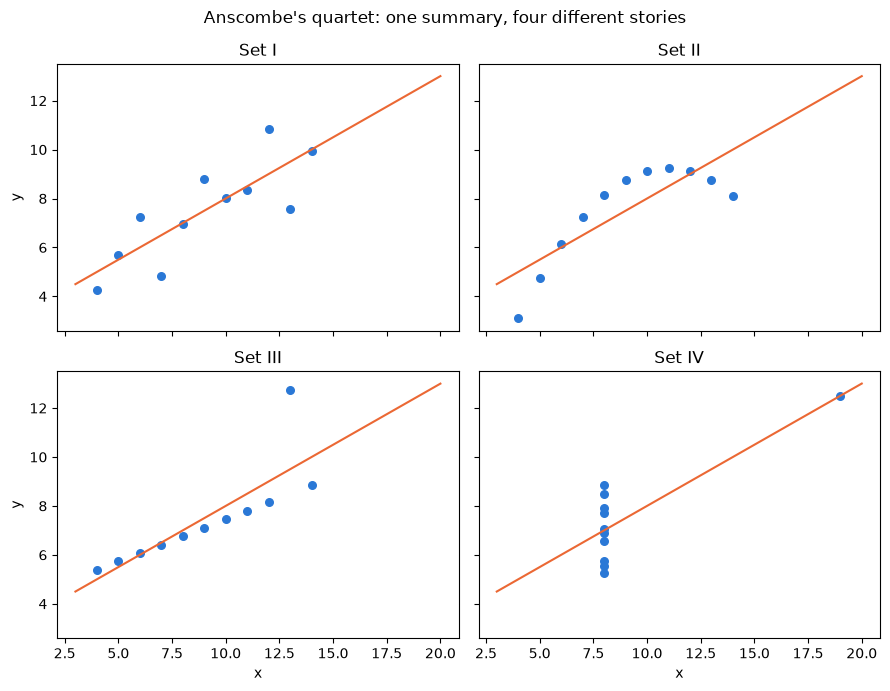

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for ax, (name, group) in zip(axes.flat, anscombe.groupby("set")):
    ax.scatter(group["x"], group["y"], color="#2a78d6", s=30)
    slope, intercept = np.polyfit(group["x"], group["y"], 1)
    xs = np.array([3, 20])
    ax.plot(xs, intercept + slope * xs, color="#eb6834", linewidth=1.5)
    ax.set_title(f"Set {name}")
for ax in axes[1]:
    ax.set_xlabel("x")
for ax in axes[:, 0]:
    ax.set_ylabel("y")
fig.suptitle("Anscombe's quartet: one summary, four different stories")
plt.tight_layout()
plt.show()

| Set | What the picture shows | What the summary hides |
|---|---|---|
| I | A noisy straight-line relationship | Nothing: here the summary is fair |
| II | A smooth curve | A straight line is the wrong model |
| III | A perfect line with one outlier | One point drags the slope and *r* |
| IV | No relationship at all, plus one extreme point | That single point creates the whole correlation |

### The Datasaurus Dozen

In 2017 Justin Matejka and George Fitzmaurice took the idea further: thirteen datasets, one of them a dinosaur, whose means, standard deviations and correlation agree to about two decimal places. The file `datasaurus_dozen.csv` holds all thirteen.

In [14]:
dozen = pd.read_csv("data/datasaurus_dozen.csv")      # Route A: "datasaurus_dozen.csv"
stats = dozen.groupby("dataset").agg(points=("x", "size"), mean_x=("x", "mean"), mean_y=("y", "mean"),
                                     sd_x=("x", "std"), sd_y=("y", "std"))
stats["r"] = dozen.groupby("dataset").apply(lambda g: g["x"].corr(g["y"]), include_groups=False)
stats.round(2)

,points,mean_x,mean_y,sd_x,sd_y,r
dataset,,,,,,
away,142,54.27,47.83,16.77,26.94,-0.06
bullseye,142,54.27,47.83,16.77,26.94,-0.07
circle,142,54.27,47.84,16.76,26.93,-0.07
dino,142,54.26,47.83,16.77,26.94,-0.06
dots,142,54.26,47.84,16.77,26.93,-0.06
h_lines,142,54.26,47.83,16.77,26.94,-0.06
high_lines,142,54.27,47.84,16.77,26.94,-0.07
slant_down,142,54.27,47.84,16.77,26.94,-0.07
slant_up,142,54.27,47.83,16.77,26.94,-0.07


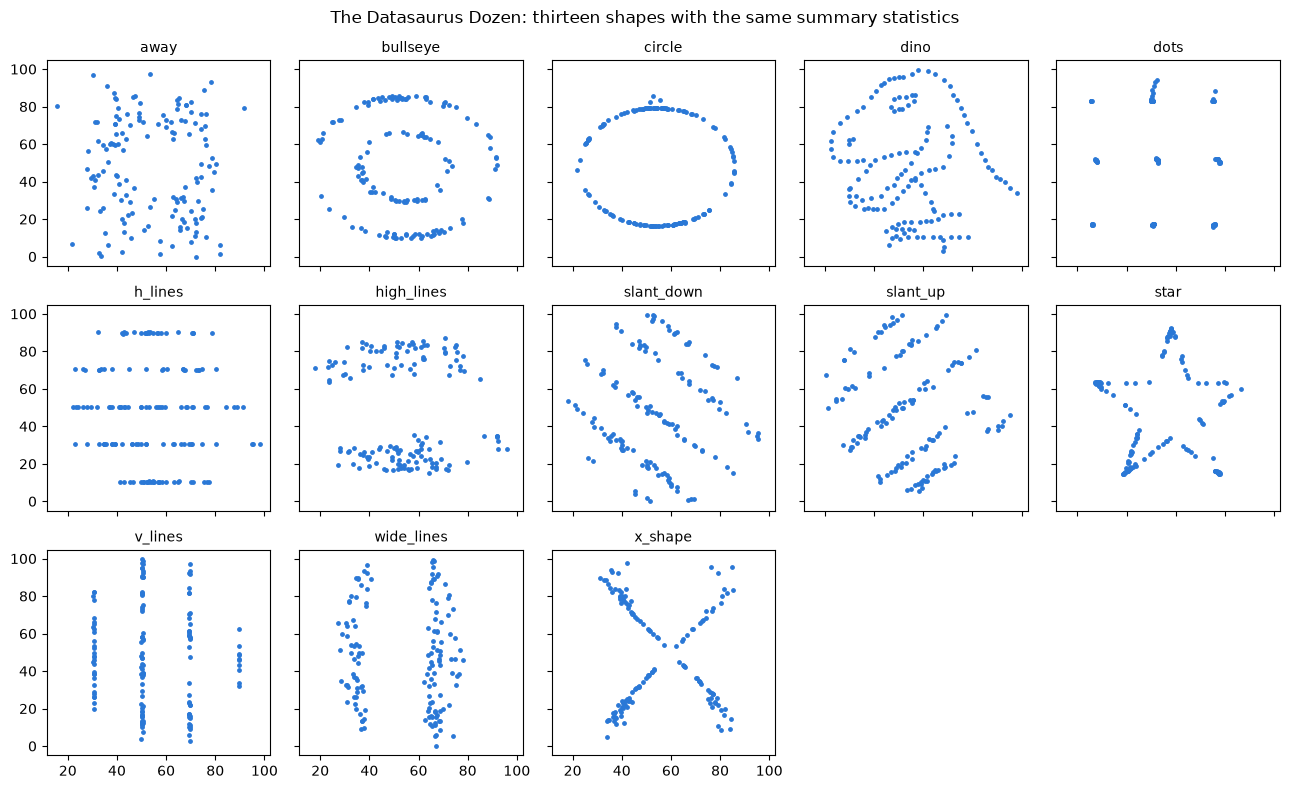

In [15]:
fig, axes = plt.subplots(3, 5, figsize=(13, 8), sharex=True, sharey=True)
for ax, (name, group) in zip(axes.flat, dozen.groupby("dataset")):
    ax.scatter(group["x"], group["y"], s=6, color="#2a78d6")
    ax.set_title(name, fontsize=10)
for ax in axes.flat[dozen["dataset"].nunique():]:
    ax.axis("off")                                          # hide the two empty panels
fig.suptitle("The Datasaurus Dozen: thirteen shapes with the same summary statistics")
plt.tight_layout()
plt.show()

> **The rule for the rest of the course**
>
> **Summarise and plot.** A summary table is a compression: it keeps a few numbers and throws the shape away. A chart shows the shape: clusters, curves, outliers, gaps. Lab 1 asks you to do both, and every later lab assumes the habit.

> **Check your understanding**
>
> A colleague sends you a correlation of 0.9 between two columns and no chart. Name two things from Anscombe's quartet that the 0.9 could be hiding.

---

## Part 7: Business case, practice, quiz and summary

### Business case for discussion: self-checkout at a supermarket chain

A supermarket chain installed self-checkout machines in 40 of its 120 stores last year. The head of operations reports that **average basket value is 18% higher** in stores with self-checkout and proposes installing machines in every remaining store.

Discuss in groups of three (15 minutes), then report one answer per question:

1. **Hierarchy.** Which level does the 18% belong to, and which level does the proposal need?
2. **Framing.** Write the framed question: decision, population (which stores, which transactions?), period (before or after installation? which months?), measure (basket value per transaction? per customer? revenue per store?).
3. **Confounding preview.** The first 40 stores were chosen because they were the **largest** and busiest. How could that alone produce an 18% gap?
4. **Data quality.** Self-checkout transactions may be recorded by a different system. Name one quality dimension that could differ between the two kinds of store.
5. **A better test.** Propose a comparison that would convince you, with the data you would need. (Hint: compare stores with themselves before and after, against similar stores without machines over the same weeks.)

### Practice

Each task works on the data already made in this notebook. Run it, answer in a sentence, then change the code as suggested.

#### Core

**Core 1.** Using `orders`, calculate the late rate (%) for **weekends versus weekdays** (`orders["date"].dt.dayofweek >= 5`). Is the difference larger or smaller than the difference between rainy and dry days?

In [16]:
orders["weekend"] = orders["date"].dt.dayofweek >= 5
(orders.groupby("weekend")["late"].mean() * 100).round(1)

weekend
False    27.0
True     22.8
Name: late, dtype: float64

**Core 2.** For each of these, name the level of the analytics hierarchy: (a) "Late night orders were 14% of September orders." (b) "Next Friday will have about 110 dinner orders." (c) "Rainy dinners are late more often because riders ride more slowly." (d) "Roster two extra riders on Friday dinners."

**Core 3.** In the `signups` table, write the code that keeps only the rows that pass **all** the checks in Part 5, and say how many customers remain.

#### Stretch

**Stretch 1.** In `standby_plan`, change `RIDER_COST` to 180 and re-run Level 4. Which decisions change? Find, by trial, the rider cost at which adding riders on **rainy dinners** stops paying.

**Stretch 2.** Write a framed version of this request, using the four elements: *"Find out whether our new app is good for business."* Then say which single chart you would show first.

**Stretch 3.** Pick two datasets from the Datasaurus Dozen and draw them side by side with a **histogram of y** for each. Do the histograms show the difference that the scatter plots show? What does that tell you about one-variable summaries?

#### Challenge

**Challenge 1.** In the bakery data, compute each branch's **weekly** median order value (customers only) and plot both branches as two lines over the twelve weeks. Mark the refurbishment period. Write two sentences for the regional manager: what the chart shows, and which period you would use to compare the branches, and why.

**Challenge 2.** Using the Level 3 approach, build a slightly better "model": past late rates by **slot, weather and distance band**. Test it on weeks 7–8. Is the average error smaller? Look at the counts: what goes wrong when the groups get small?

### Quiz

1. Name the four levels of the analytics hierarchy and the question each answers.
2. Give a business example, from any function, of a diagnostic question.
3. What are the four elements of a framed decision? Give one example of how changing the **period** can change an answer.
4. What is the difference between a statistic, an insight and a decision?
5. Which data quality dimension does each of these break: (a) the same order recorded twice; (b) "Shanghai", "shanghai" and "SH" in one column; (c) a delivery time of −5 minutes; (d) customer records last updated three years ago?
6. Why did the *Literary Digest* poll fail despite over two million responses?
7. Four datasets have the same mean, standard deviation and correlation. What should you do before reporting that they are "the same"?
8. In the QuickBite example, why was the prediction tested on weeks 7–8 instead of the weeks it was built from?

### Summary

| Idea | Remember |
|---|---|
| Data and judgement | Data records, checks and scales; people choose the question, weigh values and act |
| Analytics hierarchy | Descriptive → diagnostic → predictive → prescriptive; each level needs the one before, and assumptions grow as you climb |
| Framing | Decision, population, period, measure, plus a comparison and a threshold, written down before you look |
| Statistic → insight → decision | A number, what it means for the business, what we will do and how we will check |
| Data quality | Completeness, uniqueness, validity, consistency, accuracy, timeliness; judged as fitness for this decision |
| Summarise and plot | Identical summaries can hide completely different data |

### Sources for the cases

- Hays, C. L. (2004, 14 November). What Wal-Mart knows about customers' habits. *The New York Times*.
- Squire, P. (1988). Why the 1936 *Literary Digest* poll failed. *Public Opinion Quarterly*, 52(1), 125–133.
- Report of the Presidential Commission on the Space Shuttle Challenger Accident (1986); Tufte, E. R. (1997). *Visual explanations*. Graphics Press.
- Lazer, D., Kennedy, R., King, G., & Vespignani, A. (2014). The parable of Google Flu: Traps in big data analysis. *Science*, 343(6176), 1203–1205.
- Dastin, J. (2018, 10 October). Amazon scraps secret AI recruiting tool that showed bias against women. *Reuters*.
- Anscombe, F. J. (1973). Graphs in statistical analysis. *The American Statistician*, 27(1), 17–21.
- Matejka, J., & Fitzmaurice, G. (2017). Same stats, different graphs. *Proceedings of CHI 2017*.

**Next:** [Day 1 lecture: Exploring data](D1_lecture_exploring_data.md), then Lab 1 ([guide](guides/lab1_data_exploration.md)).

---

## For the facilitator

This notebook fills periods P1–P3 of Day 1; the [exploring data lecture](D1_lecture_exploring_data.md) fills P4–P6. No answers are given here.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P1 | 10 | Part 1: course on one page, three environments, habits | Show the overview and timetable pages; check every student can open a notebook |
| P1 | 35 | Part 2: why data, biases, the cases table | Tell two cases as stories (one success, one failure); run the pair discussion and collect answers on the board for Part 4 |
| P2 | 15 | Part 3: the hierarchy tables | Ask students for one example per cell of the functions table from their own experience |
| P2 | 30 | Part 3: QuickBite worked example, all four levels | Run every cell live; insist on predictions before the late-rate and largest-error cells; change `REDUCTION` live |
| P3 | 15 | Part 4: framing, the bakery example | Let students vote on the winning branch before running; return to the pair-discussion answers |
| P3 | 15 | Part 5: data quality dimensions | Have students name the dimension of each planted problem before running the checks |
| P3 | 15 | Part 6: Anscombe and Datasaurus | Hide the plots until predictions are written; end on "summarise and plot" as the bridge to P4 |

The business case, the practice tasks and the quiz are for the evening or for groups who move faster; the self-checkout case also works as a warm-up on Day 2. Do not discuss Lab 1's questions or the diamonds data in these periods.